In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from PIL import Image

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("All libraries are working!")

TensorFlow: 2.21.0
NumPy: 2.5.4
Pandas: 3.0.6
Scikit-learn: 1.9.1
All libraries are working!


In [2]:
from pathlib import Path

dataset_path = Path(
    r"C:\Users\92335\Documents\Waste_AI_Final\Garbage classification\Garbage classification"
)

print("Dataset folder exists:", dataset_path.exists())

for folder in sorted(dataset_path.iterdir()):
    if folder.is_dir():
        images = list(folder.glob("*"))
        print(f"{folder.name}: {len(images)} files")

Dataset folder exists: True
cardboard: 403 files
glass: 501 files
metal: 410 files
paper: 594 files
plastic: 482 files
trash: 137 files


In [3]:
from PIL import Image
from pathlib import Path

for folder in sorted(dataset_path.iterdir()):
    if folder.is_dir():
        valid_images = 0
        invalid_files = []

        for file in folder.iterdir():
            try:
                with Image.open(file) as img:
                    img.verify()
                valid_images += 1
            except Exception:
                invalid_files.append(file.name)

        print(
            f"{folder.name}: "
            f"{valid_images} valid images, "
            f"{len(invalid_files)} invalid files"
        )

cardboard: 403 valid images, 0 invalid files
glass: 501 valid images, 0 invalid files
metal: 410 valid images, 0 invalid files
paper: 594 valid images, 0 invalid files
plastic: 482 valid images, 0 invalid files
trash: 137 valid images, 0 invalid files


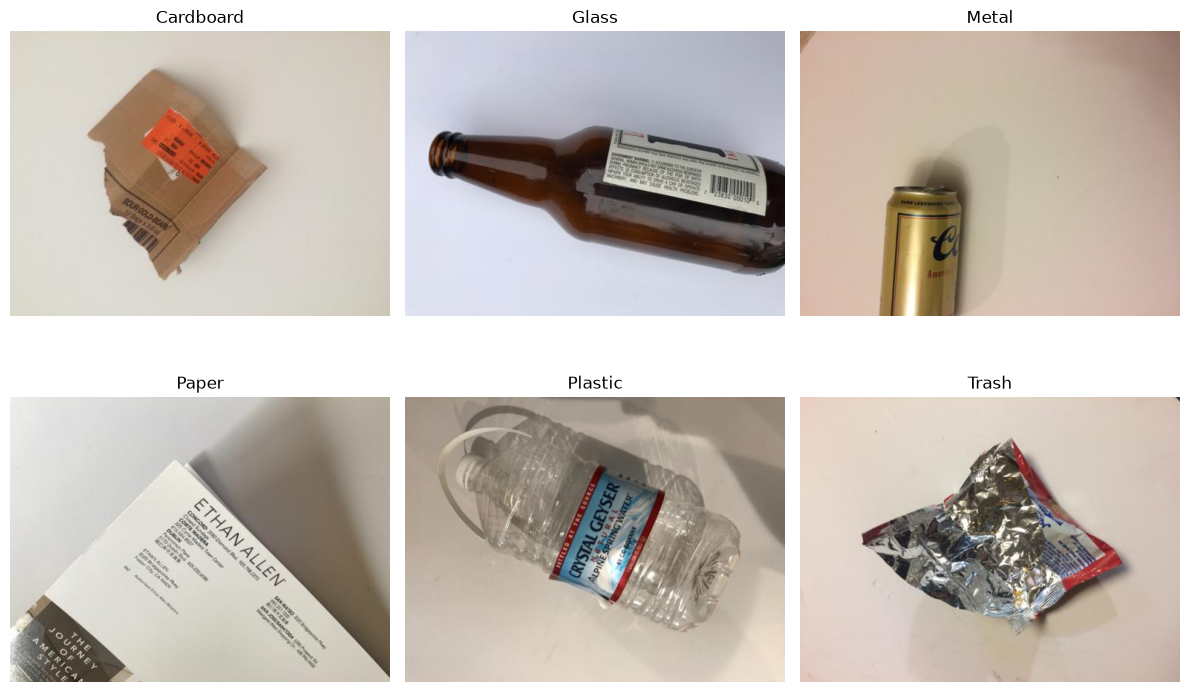

In [4]:
import matplotlib.pyplot as plt
import random
from PIL import Image

categories = sorted([
    folder.name for folder in dataset_path.iterdir()
    if folder.is_dir()
])

plt.figure(figsize=(12, 8))

for i, category in enumerate(categories):
    image_files = [
        file for file in (dataset_path / category).iterdir()
        if file.is_file()
    ]

    image_path = random.choice(image_files)

    with Image.open(image_path) as img:
        plt.subplot(2, 3, i + 1)
        plt.imshow(img.convert("RGB"))
        plt.title(category.capitalize())
        plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import load_img, img_to_array

IMAGE_SIZE = (128, 128)
images = []
labels = []

categories = sorted([
    folder.name for folder in dataset_path.iterdir()
    if folder.is_dir()
])

for label, category in enumerate(categories):
    folder = dataset_path / category

    for image_path in folder.iterdir():
        if image_path.is_file():
            try:
                img = load_img(
                    image_path,
                    target_size=IMAGE_SIZE
                )
                img_array = img_to_array(img)
                images.append(img_array)
                labels.append(label)
            except Exception as e:
                print("Skipped:", image_path.name, e)

X = np.array(images, dtype=np.float32) / 255.0
y = np.array(labels)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Categories:", categories)
print("Total images:", len(X))
print("Training images:", len(X_train))
print("Testing images:", len(X_test))
print("Image shape:", X_train.shape[1:])
print("Number of classes:", len(categories))

Categories: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Total images: 2527
Training images: 2021
Testing images: 506
Image shape: (128, 128, 3)
Number of classes: 6


In [6]:
import tensorflow as tf
from tensorflow.keras import layers, models

tf.random.set_seed(42)

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(len(categories), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 6)                   │             774 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,305,414 (12.61 MB)

 Trainable params: 3,305,414 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 183s 1s/step - accuracy: 0.2432 - loss: 1.7473 - val_accuracy: 0.4247 - val_loss: 1.5769
Epoch 2/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 31s 572ms/step - accuracy: 0.3923 - loss: 1.4926 - val_accuracy: 0.4444 - val_loss: 1.4417
Epoch 3/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 28s 526ms/step - accuracy: 0.4381 - loss: 1.3857 - val_accuracy: 0.5086 - val_loss: 1.3849
Epoch 4/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 26s 500ms/step - accuracy: 0.4858 - loss: 1.2969 - val_accuracy: 0.5259 - val_loss: 1.3178
Epoch 5/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 26s 508ms/step - accuracy: 0.5248 - loss: 1.2222 - val_accuracy: 0.5457 - val_loss: 1.2546
Epoch 6/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 26s 515ms/step - accuracy: 0.5625 - loss: 1.1419 - val_accuracy: 0.5407 - val_loss: 1.2298
Epoch 7/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 27s 521ms/step - accuracy: 0.5860 - loss: 1.0914 - val_accuracy: 0.5185 - val_loss: 1.2075
Epoch 8/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 26s 508ms/step - accuracy: 0.6300 - loss: 1.0072 - val_accura

16/16 ━━━━━━━━━━━━━━━━━━━━ 49s 1s/step - accuracy: 0.6304 - loss: 1.1441  

Test Accuracy: 63.04%
Test Loss: 1.1441
16/16 ━━━━━━━━━━━━━━━━━━━━ 20s 737ms/step

Classification Report:

              precision    recall  f1-score   support

   cardboard       0.77      0.77      0.77        81
       glass       0.67      0.55      0.60       100
       metal       0.52      0.57      0.55        82
       paper       0.61      0.79      0.69       119
     plastic       0.62      0.57      0.59        97
       trash       0.55      0.22      0.32        27

    accuracy                           0.63       506
   macro avg       0.62      0.58      0.59       506
weighted avg       0.63      0.63      0.62       506



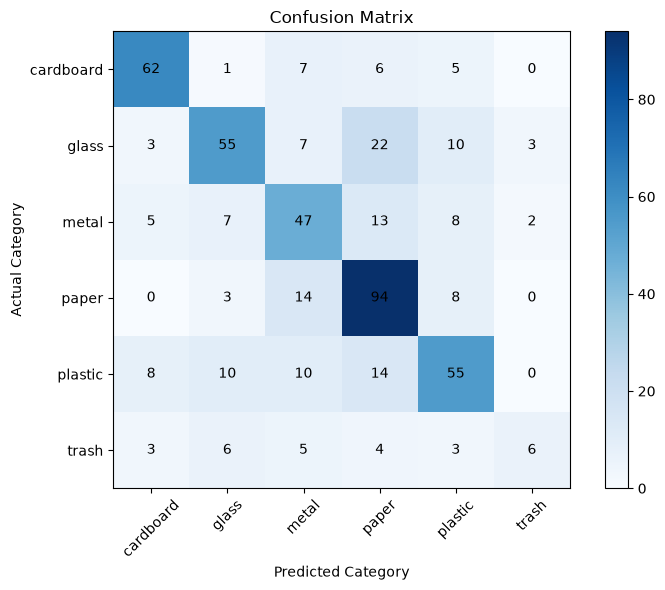

In [8]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

# Evaluate on the separate test set
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=1
)

print(f"\nTest Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

# Predict the categories of test images
y_prob = model.predict(X_test, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Detailed performance for each category
print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred,
    labels=range(len(categories)),
    target_names=categories,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test, y_pred,
    labels=range(len(categories))
)

plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(range(len(categories)), categories, rotation=45)
plt.yticks(range(len(categories)), categories)
plt.colorbar()

for i in range(len(categories)):
    for j in range(len(categories)):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

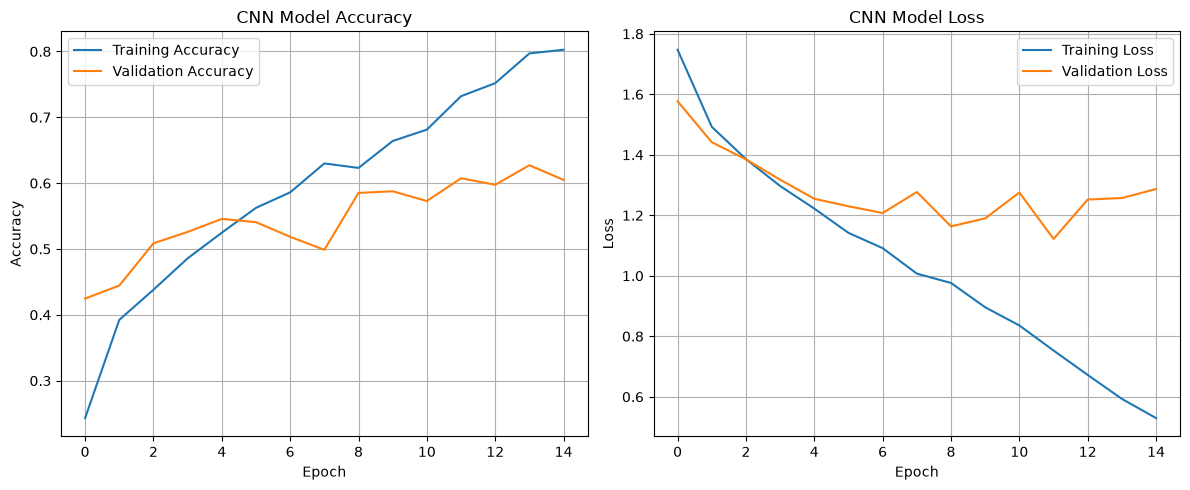

In [9]:
import matplotlib.pyplot as plt

# Plot accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Plot loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [10]:
from collections import Counter

print("Training images:", X_train.shape[0])
print("Testing images:", X_test.shape[0])
print("\nTraining images per category:")

for label, category in enumerate(categories):
    print(f"{category}: {Counter(y_train)[label]}")

Training images: 2021
Testing images: 506

Training images per category:
cardboard: 322
glass: 401
metal: 328
paper: 475
plastic: 385
trash: 110


In [11]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.random.set_seed(42)

# Data augmentation: applied only during training
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
])

# Build the improved CNN
improved_model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    data_augmentation,

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(len(categories), activation="softmax")
])

improved_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

improved_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)            │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 128, 128, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 128, 128, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 64, 64, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 64, 64, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 32, 32, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 32, 32, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 6)                   │             774 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 111,430 (435.27 KB)

 Trainable params: 110,982 (433.52 KB)

 Non-trainable params: 448 (1.75 KB)

In [12]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

improved_history = improved_model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 164s 2s/step - accuracy: 0.4635 - loss: 1.4137 - val_accuracy: 0.2099 - val_loss: 1.8156 - learning_rate: 0.0010
Epoch 2/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 67s 1s/step - accuracy: 0.5600 - loss: 1.2207 - val_accuracy: 0.2099 - val_loss: 1.9871 - learning_rate: 0.0010
Epoch 3/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5959 - loss: 1.1087
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
51/51 ━━━━━━━━━━━━━━━━━━━━ 66s 1s/step - accuracy: 0.5959 - loss: 1.1087 - val_accuracy: 0.2222 - val_loss: 1.9632 - learning_rate: 0.0010
Epoch 4/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 67s 1s/step - accuracy: 0.6324 - loss: 1.0227 - val_accuracy: 0.2025 - val_loss: 2.0564 - learning_rate: 5.0000e-04
Epoch 5/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6473 - loss: 0.9737
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
51/51 ━━━━━━━━━━━━━━━━━━━━ 65s 1s/step - accuracy: 0.6473 - loss: 0.9737 - val_accuracy:

In [13]:
print("Training epochs completed:", len(improved_history.history["accuracy"]))
print("Best validation accuracy:", max(improved_history.history["val_accuracy"]))

Training epochs completed: 5
Best validation accuracy: 0.2370370328426361


In [14]:
import pandas as pd

history_df = pd.DataFrame(improved_history.history)
print(history_df[["accuracy", "val_accuracy", "loss", "val_loss"]].round(4))

   accuracy  val_accuracy    loss  val_loss
0    0.4635        0.2099  1.4137    1.8156
1    0.5600        0.2099  1.2207    1.9871
2    0.5959        0.2222  1.1087    1.9632
3    0.6324        0.2025  1.0227    2.0564
4    0.6473        0.2370  0.9737    1.8750


In [15]:
from sklearn.model_selection import train_test_split
from collections import Counter

X_train_check, X_val_check, y_train_check, y_val_check = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Validation images:", len(y_val_check))
print("Validation class counts:")

for i, category in enumerate(categories):
    print(category, ":", sum(y_val_check == i))

Validation images: 405
Validation class counts:
cardboard : 65
glass : 80
metal : 66
paper : 95
plastic : 77
trash : 22


In [16]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("Pixel minimum:", X_train.min())
print("Pixel maximum:", X_train.max())

print("Label values:", sorted(set(y_train)))
print("Categories:", categories)

X_train shape: (2021, 128, 128, 3)
y_train shape: (2021,)
Pixel minimum: 0.0
Pixel maximum: 1.0
Label values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Categories: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [17]:
original_loss, original_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Original CNN test accuracy: {original_accuracy * 100:.2f}%")
print(f"Original CNN test loss: {original_loss:.4f}")

Original CNN test accuracy: 63.04%
Original CNN test loss: 1.1441


In [18]:
improved_loss, improved_accuracy = improved_model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Improved CNN test accuracy: {improved_accuracy * 100:.2f}%")
print(f"Improved CNN test loss: {improved_loss:.4f}")

Improved CNN test accuracy: 23.52%
Improved CNN test loss: 1.8034


In [19]:
import numpy as np
from collections import Counter

predictions = improved_model.predict(X_test, verbose=0)
predicted_classes = np.argmax(predictions, axis=1)

print("Predicted class counts:")

for i, category in enumerate(categories):
    print(f"{category}: {np.sum(predicted_classes == i)}")

print("\nActual class counts:")

for i, category in enumerate(categories):
    print(f"{category}: {np.sum(y_test == i)}")

Predicted class counts:
cardboard: 0
glass: 0
metal: 0
paper: 506
plastic: 0
trash: 0

Actual class counts:
cardboard: 81
glass: 100
metal: 82
paper: 119
plastic: 97
trash: 27


In [20]:
print("Prediction probabilities for the first 5 test images:\n")

for i in range(5):
    print(f"Image {i + 1}:")
    for j, category in enumerate(categories):
        print(f"  {category}: {predictions[i][j]:.4f}")

Prediction probabilities for the first 5 test images:

Image 1:
  cardboard: 0.0908
  glass: 0.2081
  metal: 0.0853
  paper: 0.3089
  plastic: 0.1827
  trash: 0.1243
Image 2:
  cardboard: 0.0890
  glass: 0.2079
  metal: 0.0817
  paper: 0.3071
  plastic: 0.1820
  trash: 0.1323
Image 3:
  cardboard: 0.0877
  glass: 0.2036
  metal: 0.0844
  paper: 0.2913
  plastic: 0.2152
  trash: 0.1178
Image 4:
  cardboard: 0.0865
  glass: 0.2028
  metal: 0.0823
  paper: 0.3103
  plastic: 0.1936
  trash: 0.1246
Image 5:
  cardboard: 0.0879
  glass: 0.2064
  metal: 0.0819
  paper: 0.3072
  plastic: 0.1853
  trash: 0.1313


In [21]:
print("Categories:", categories)

print("\nOriginal model output classes:", model.output_shape[-1])
print("Improved model output classes:", improved_model.output_shape[-1])

print("\nOriginal model final layer:")
print(model.layers[-1])

print("\nImproved model final layer:")
print(improved_model.layers[-1])

Categories: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']

Original model output classes: 6
Improved model output classes: 6

Original model final layer:
<Dense name=dense_1, built=True>

Improved model final layer:
<Dense name=dense_3, built=True>


In [22]:
from pathlib import Path

save_path = Path(
    r"C:\Users\92335\Documents\Waste_AI_Final\waste_classifier_model.keras"
)

model.save(save_path)

print("Original model saved successfully!")
print("Saved at:", save_path)

Original model saved successfully!
Saved at: C:\Users\92335\Documents\Waste_AI_Final\waste_classifier_model.keras


In [23]:
from tensorflow.keras.models import load_model

saved_model = load_model(
    r"C:\Users\92335\Documents\Waste_AI_Final\waste_classifier_model.keras"
)

print("Saved model loaded successfully!")
print("Input shape:", saved_model.input_shape)
print("Output shape:", saved_model.output_shape)

Saved model loaded successfully!
Input shape: (None, 128, 128, 3)
Output shape: (None, 6)


In [24]:
%pip install gradio

  Using cached gradio-6.30.0-py3-none-any.whl.metadata (16 kB)
  Using cached gradio_client-2.7.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached groovy-0.1.2-py3-none-any.whl.metadata (6.1 kB)
  Using cached hf_gradio-0.4.1-py3-none-any.whl.metadata (428 bytes)
  Using cached huggingface_hub-2.2.0-py3-none-any.whl.metadata (16 kB)
  Using cached pydantic-2.14.1-py3-none-any.whl.metadata (133 kB)
  Using cached pydub-0.25.1-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached python_multipart-0.0.32-py3-none-any.whl.metadata (2.1 kB)
  Using cached pytz-2026.5-py2.py3-none-any.whl.metadata (22 kB)
  Using cached safehttpx-0.1.7-py3-none-any.whl.metadata (4.2 kB)
  Using cached semantic_version-2.10.0-py2.py3-none-any.whl.metadata (9.7 kB)
  Using cached tomlkit-0.14.0-py3-none-any.whl.metadata (2.8 kB)
  Using cached typer-0.27.3-py3-none-any.whl.metadata (16 kB)
  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata

  You can safely remove it manually.


In [25]:
import gradio as gr
import tensorflow as tf

print("Gradio version:", gr.__version__)
print("TensorFlow version:", tf.__version__)
print("Model ready:", saved_model is not None)

C:\Users\92335\miniconda3\envs\waste_ai\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Gradio version: 6.30.0
TensorFlow version: 2.21.0
Model ready: True


In [26]:

import gradio as gr
import numpy as np
from PIL import Image
from tensorflow.keras.models import load_model

# Load the trained model
model = load_model(
    r"C:\Users\92335\Documents\Waste_AI_Final\waste_classifier_model.keras"
)

# Waste categories in the correct model-output order
categories = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

def classify_waste(image):
    if image is None:
        return {"No image uploaded": 1.0}

    # Prepare the uploaded image
    image = image.convert("RGB")
    image = image.resize((128, 128))

    image_array = np.array(image, dtype=np.float32) / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    # Predict the waste category
    predictions = model.predict(image_array, verbose=0)[0]

    # Return confidence scores for all categories
    return {
        categories[i]: float(predictions[i])
        for i in range(len(categories))
    }

# Create the Gradio interface
demo = gr.Interface(
    fn=classify_waste,
    inputs=gr.Image(type="pil", label="Upload a Waste Image"),
    outputs=gr.Label(
        num_top_classes=6,
        label="Waste Classification Results"
    ),
    title="AI Waste Classification and Recycling Assistant",
    description=(
        "Upload an image of cardboard, glass, metal, paper, "
        "plastic, or trash. The CNN model predicts its category "
        "and displays confidence scores."
    )
)

demo.launch()


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [27]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(160, 160, 3)
)

print("Pretrained model loaded successfully!")
print("Input shape:", base_model.input_shape)
print("Output shape:", base_model.output_shape)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 9s 1us/step
Pretrained model loaded successfully!
Input shape: (None, 160, 160, 3)
Output shape: (None, 5, 5, 1280)


In [2]:
print("Jupyter is working !")

Jupyter is working !


In [5]:

import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

dataset_path = r"C:\Users\92335\Documents\Waste_AI_Final\Garbage classification\Garbage classification"

categories = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]

train_ds = image_dataset_from_directory(
    dataset_path,
    class_names=categories,
    image_size=(160, 160),
    batch_size=32,
    validation_split=0.2,
    subset="training",
    seed=42,
    label_mode="int"
)

test_ds = image_dataset_from_directory(
    dataset_path,
    class_names=categories,
    image_size=(160, 160),
    batch_size=32,
    validation_split=0.2,
    subset="validation",
    seed=42,
    label_mode="int"
)

def prepare_images(images, labels):
    images = preprocess_input(images)
    return images, labels

train_ds = train_ds.map(prepare_images)
test_ds = test_ds.map(prepare_images)

print("Training and testing datasets prepared!")
print("Classes:", categories)


Found 2527 files belonging to 6 classes.
Using 2022 files for training.
Found 2527 files belonging to 6 classes.
Using 505 files for validation.
Training and testing datasets prepared!
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [6]:

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# Load the pretrained MobileNetV2 base
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(160, 160, 3)
)

# Freeze pretrained layers initially
base_model.trainable = False

# Build the waste classification model
model = models.Sequential([
    layers.Input(shape=(160, 160, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(6, activation="softmax")
])

# Compile model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()
print("MobileNetV2 waste classifier built successfully!")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_160 (Functional)    │ (None, 5, 5, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 6)                   │             774 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

MobileNetV2 waste classifier built successfully!


In [7]:

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=10,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

print("Training completed!")


C:\Users\92335\miniconda3\envs\waste_ai\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 128s 805ms/step - accuracy: 0.6449 - loss: 0.9845 - val_accuracy: 0.7505 - val_loss: 0.6540 - learning_rate: 0.0010
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 45s 708ms/step - accuracy: 0.8086 - loss: 0.5367 - val_accuracy: 0.8040 - val_loss: 0.5378 - learning_rate: 0.0010
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 45s 707ms/step - accuracy: 0.8591 - loss: 0.4043 - val_accuracy: 0.8040 - val_loss: 0.5149 - learning_rate: 0.0010
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 46s 709ms/step - accuracy: 0.8630 - loss: 0.3685 - val_accuracy: 0.8198 - val_loss: 0.5242 - learning_rate: 0.0010
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 83s 729ms/step - accuracy: 0.8853 - loss: 0.3168 - val_accuracy: 0.8178 - val_loss: 0.4969 - learning_rate: 0.0010
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 82s 729ms/step - accuracy: 0.9055 - loss: 0.2448 - val_accuracy: 0.8356 - val_loss: 0.4674 - learning_rate: 0.0010
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 82s 729ms/step - accuracy: 0.9189 - loss: 0

In [8]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

save_path = r"C:\Users\92335\Documents\Waste_AI_Final\waste_classifier_mobilenetv2.keras"

model.save(save_path)

print("Model saved successfully!")
print("Saved at:", save_path)


16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 555ms/step - accuracy: 0.8297 - loss: 0.4616
Test Loss: 0.4616
Test Accuracy: 82.97%
Model saved successfully!
Saved at: C:\Users\92335\Documents\Waste_AI_Final\waste_classifier_mobilenetv2.keras


In [11]:

import gradio as gr
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Load the trained model
model = load_model(
    r"C:\Users\92335\Documents\Waste_AI_Final\waste_classifier_mobilenetv2.keras"
)

categories = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]

recycling_tips = {
    "cardboard": "Keep cardboard dry and clean before placing it in paper recycling.",
    "glass": "Separate glass from other waste and follow your local glass recycling rules.",
    "metal": "Empty metal cans and containers before recycling them.",
    "paper": "Keep paper clean and dry for paper recycling.",
    "plastic": "Check the recycling symbol and your local recycling guidelines.",
    "trash": "This item may need general-waste disposal. Check local waste guidelines."
}

def classify_waste(image):
    if image is None:
        return {}, "Please upload an image first."

    image = image.convert("RGB").resize((160, 160))
    image_array = np.array(image, dtype=np.float32)
    image_array = preprocess_input(image_array)
    image_array = np.expand_dims(image_array, axis=0)

    predictions = model.predict(image_array, verbose=0)[0]

    results = {
        categories[i]: float(predictions[i])
        for i in range(len(categories))
    }

    predicted_category = categories[int(np.argmax(predictions))]
    confidence = float(np.max(predictions)) * 100

    advice = f"""
### ♻️ Identified: {predicted_category.title()}

**Model confidence:** {confidence:.1f}%

---

**Recycling guidance**

{recycling_tips[predicted_category]}
"""

    return results, advice


custom_css = """
body {
    background: #071a14 !important;
}

.gradio-container {
    background: radial-gradient(
        ellipse at top,
        #123d30 0%,
        #071f19 60%,
        #06130f 100%
    ) !important;
    color: #ecfdf5 !important;
    max-width: 1200px !important;
    margin: auto !important;
}

#eco-header {
    text-align: left;
    padding: 28px;
    border: 1px solid #28644d;
    border-radius: 24px;
    background: linear-gradient(135deg, #123d30, #0a261d);
    margin-bottom: 22px;
}

#eco-brand {
    display: flex;
    align-items: center;
    gap: 15px;
    margin-bottom: 26px;
}

#eco-logo {
    background: #0d5c43;
    width: 58px;
    height: 58px;
    border-radius: 16px;
    display: flex;
    align-items: center;
    justify-content: center;
    font-size: 32px;
    flex-shrink: 0;
}

#eco-brand h2 {
    color: #ecfdf5;
    margin: 0;
    font-size: 27px;
}

#eco-brand p {
    color: #a7dcc6;
    margin: 5px 0 0 0;
    font-size: 13px;
}

#eco-status {
    margin-left: auto;
    padding: 7px 12px;
    border-radius: 20px;
    background: #164e3a;
    color: #6ee7b7;
    font-size: 12px;
    white-space: nowrap;
}

#eco-heading {
    color: #ecfdf5;
    font-size: clamp(28px, 4vw, 40px);
    line-height: 1.15;
    margin: 0 0 12px 0;
}

#eco-subheading {
    color: #a7dcc6;
    font-size: 16px;
    line-height: 1.7;
    margin-bottom: 22px;
}

#eco-categories {
    display: flex;
    flex-wrap: wrap;
    gap: 8px;
    margin-bottom: 4px;
}

.eco-chip {
    background: #103d2f;
    border: 1px solid #28644d;
    color: #c1e8d5;
    border-radius: 20px;
    padding: 7px 11px;
    font-size: 12px;
}

.eco-panel {
    background: #103d2f !important;
    border: 1px solid #28644d !important;
    border-radius: 20px !important;
    padding: 20px !important;
}

#eco-upload-title {
    color: #ecfdf5;
    font-size: 21px;
    margin-bottom: 6px;
}

#eco-upload-subtitle {
    color: #a7dcc6;
    font-size: 13px;
    line-height: 1.6;
    margin-bottom: 16px;
}

#eco-button {
    background: linear-gradient(90deg, #059669, #10b981) !important;
    color: white !important;
    border: none !important;
    border-radius: 12px !important;
    min-height: 52px !important;
    font-size: 16px !important;
    font-weight: 700 !important;
    box-shadow: 0 5px 18px rgba(16, 185, 129, 0.15);
}

#eco-button:hover {
    background: linear-gradient(90deg, #047857, #059669) !important;
}

#eco-footer {
    text-align: center;
    color: #a7dcc6;
    font-size: 12px;
    padding: 20px 8px 8px;
}

footer {
    display: none !important;
}

@media (max-width: 600px) {
    #eco-header {
        padding: 20px;
    }

    #eco-status {
        display: none;
    }
}
"""

with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="emerald",
        secondary_hue="green",
        neutral_hue="slate"
    ),
    css=custom_css,
    title="EcoSort AI | Waste Classification"
) as demo:

    # Premium emerald-green header
    gr.HTML("""
    <div id="eco-header">

        <div id="eco-brand">
            <div id="eco-logo">♻</div>
            <div>
                <h2>EcoSort AI</h2>
                <p>AI Waste Classification &amp; Recycling</p>
            </div>
            <div id="eco-status">● AI Powered</div>
        </div>

        <h1 id="eco-heading">
            A smarter way to sort waste.
        </h1>

        <div id="eco-subheading">
            Upload a waste image and let AI identify its category in seconds.
        </div>

        <div id="eco-categories">
            <span class="eco-chip">Cardboard</span>
            <span class="eco-chip">Glass</span>
            <span class="eco-chip">Metal</span>
            <span class="eco-chip">Paper</span>
            <span class="eco-chip">Plastic</span>
            <span class="eco-chip">Trash</span>
        </div>

    </div>
    """)

    # Main upload and result panel
    with gr.Column(elem_classes=["eco-panel"]):

        gr.HTML("""
        <div id="eco-upload-title">
            ☁️ Upload your waste image
        </div>
        <div id="eco-upload-subtitle">
            Choose an image of cardboard, glass, metal, paper, plastic or trash.
        </div>
        """)

        image_input = gr.Image(
            type="pil",
            label="Choose an image to classify",
            height=300
        )

        classify_button = gr.Button(
            "♻  Classify Waste",
            variant="primary",
            elem_id="eco-button",
            size="lg"
        )

        result_output = gr.Label(
            num_top_classes=6,
            label="Waste Classification Results"
        )

        advice_output = gr.Markdown(
            "Your waste category and recycling guidance will appear here."
        )

    gr.HTML("""
    <div id="eco-footer">
        A cleaner interface for a greener future ♻️
        <br><br>
        Built with TensorFlow · MobileNetV2 · Gradio
    </div>
    """)

    classify_button.click(
        fn=classify_waste,
        inputs=image_input,
        outputs=[result_output, advice_output]
    )

demo.launch(server_port=7862)


C:\Users\92335\AppData\Local\Temp\ipykernel_13472\1568280799.py:210: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


* Running on local URL:  http://127.0.0.1:7862
* To create a public link, set `share=True` in `launch()`.
